In [2]:
# INSTALLING PACKAGES & IMPORT LIBRARIES

!pip install -q anywidget
import numpy as np, matplotlib.pyplot as plt, xarray as xr
import plotly.express as px, plotly.graph_objects as go, ipywidgets as w
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

['/kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_MASK_001_20260211T080401_2604206_018.nc', '/kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc']
mask layers: ['Cloud flag', 'Cirrus flag', 'Water flag', 'Spacecraft Flag', 'Dilated Cloud Flag', 'AOD550', 'H2O (g cm-2)', 'Aggregate Flag']


Text(0.5, 1.0, 'Flagged pixels (white)')

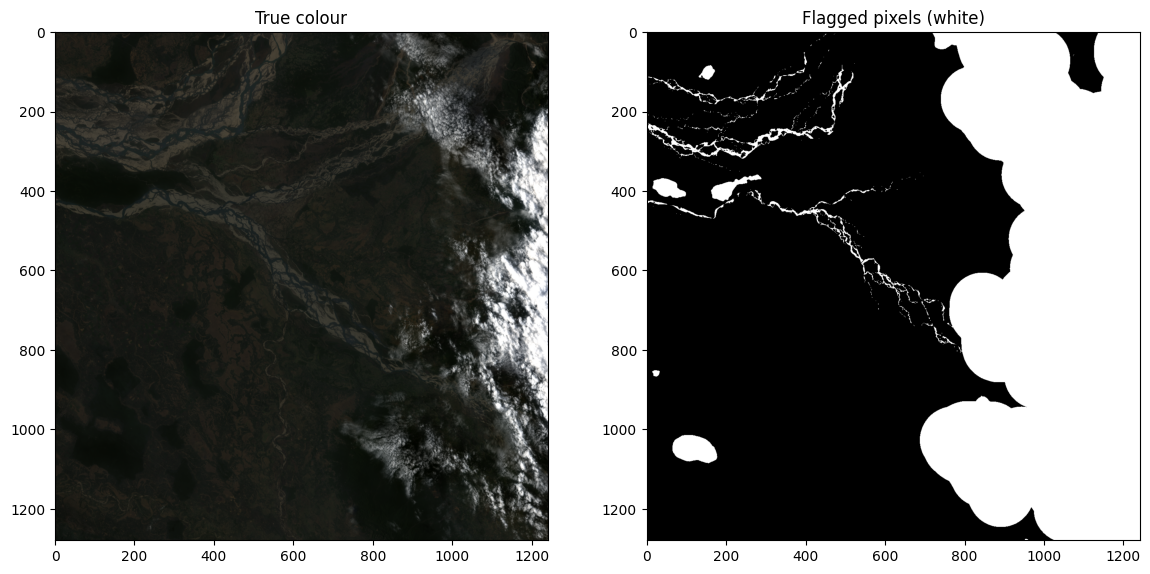

In [3]:
# LOADING THE EMIT SCENE + MASK FROM KAGGLE DATASET AND DISPLAY

from glob import glob
scene = "20260211T080401_2604206_018"                                # date, time and ID in the file name
files = glob(f"/kaggle/input/**/*{scene}*.nc", recursive=True); print(files)
assert files, "No EMIT files found: add the EMIT_60233 dataset with 'Add Input' (right-hand panel)"
f      = [x for x in files if "_RFL_" in x][0]                          # reflectance file
mask_f = [x for x in files if "_MASK_" in x][0]                         # mask file

ds = xr.open_dataset(f)                                          # the reflectance cube + metadata
bp = xr.open_dataset(f, group="sensor_band_parameters")          # wavelengths + good-band flags
good = bp.good_wavelengths.values == 1                           # drop the water-vapour absorption bands
img  = ds.reflectance[:, :, good].values                         # (rows, cols, bands)
img.clip(0, 1, out=img)                                          # fill values (-9999) -> 0
wl   = bp.wavelengths.values[good]                               # nm
band = lambda nm: np.argmin(abs(wl - nm))                        # wavelength (nm) -> band index
stretch = lambda x: np.clip(x / np.percentile(x, 99), 0, 1)      # brighten an image for display

mk     = xr.open_dataset(mask_f)
mnames = list(xr.open_dataset(mask_f, group="sensor_band_parameters").mask_bands.values)
print("mask layers:", mnames)
flag   = mk["mask"].values[:, :, mnames.index("Aggregate Flag")]   # 1 = cloud / water / bad pixel

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1); plt.imshow(stretch(img[:, :, [band(650), band(560), band(470)]])); plt.title("True colour")
plt.subplot(1, 2, 2); plt.imshow(flag, cmap="gray"); plt.title("Flagged pixels (white)")

In [4]:
# DETAILS OF THE IMAGE CUBE

print(f"number of rows    = {img.shape[0]}")
print(f"number of columns = {img.shape[1]}")
print(f"number of bands   = {img.shape[2]}")
print(wl)
ds          # the file's metadata

number of rows    = 1280
number of columns = 1242
number of bands   = 255
[ 380.85788  388.26147  395.6681   403.0777   410.49026  417.90585
  425.32443  432.745    440.16953  447.5951   455.0226   462.45114
  469.8827   477.3152   484.7497   492.1852   499.6237   507.0622
  514.5027   521.9432   529.3856   536.8291   544.27356  551.719
  559.16644  566.6139   574.06134  581.5108   588.9602   596.41064
  603.86206  611.3145   618.7669   626.22034  633.67377  641.1282
  648.5826   656.03796  663.4934   670.94977  678.4062   685.8626
  693.32     700.7774   708.2358   715.6932   723.1516   730.61096
  738.0694   745.5288   752.9882   760.4486   767.908    775.3684
  782.8298   790.2902   797.75165  805.21405  812.6754   820.13684
  827.59827  835.0597   842.5221   849.9835   857.446    864.9074
  872.3699   879.8323   887.29376  894.7562   902.2187   909.68115
  917.1436   924.6061   932.06854  939.53107  946.99255  954.455
  961.9165   969.379    976.8406   984.30206  991.7636   999.225

<xarray.Dataset> Size: 2GB
Dimensions:      (downtrack: 1280, crosstrack: 1242, bands: 285)
Dimensions without coordinates: downtrack, crosstrack, bands
Data variables:
    reflectance  (downtrack, crosstrack, bands) float32 2GB ...
Attributes: (12/37)
    ncei_template_version:             NCEI_NetCDF_Swath_Template_v2.0
    summary:                           The Earth Surface Mineral Dust Source ...
    keywords:                          Imaging Spectroscopy, minerals, EMIT, ...
    Conventions:                       CF-1.63
    sensor:                            EMIT (Earth Surface Mineral Dust Sourc...
    instrument:                        EMIT
    ...                                ...
    southernmost_latitude:             27.244149226163522
    spatialResolution:                 0.000542232520256367
    spatial_ref:                       GEOGCS["WGS 84",DATUM["WGS_1984",SPHER...
    geotransform:                      [ 9.51918961e+01  5.42232520e-04 -0.00...
    day_night_flag:                    Day
    title:                             EMIT L2A Estimated Surface Reflectance...

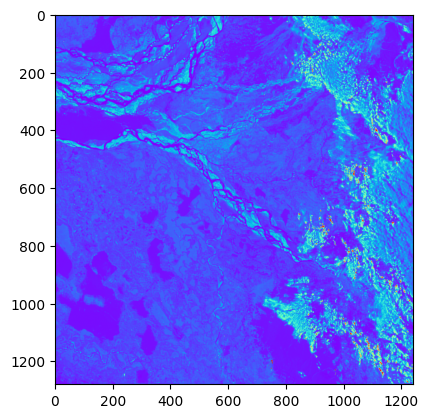

In [5]:
plt.imshow(img[:, :, 254], cmap = 'rainbow')

R = band 231 at 2322.8 nm,  G = band 163 at 1647.6 nm,  B = band 23 at 551.7 nm


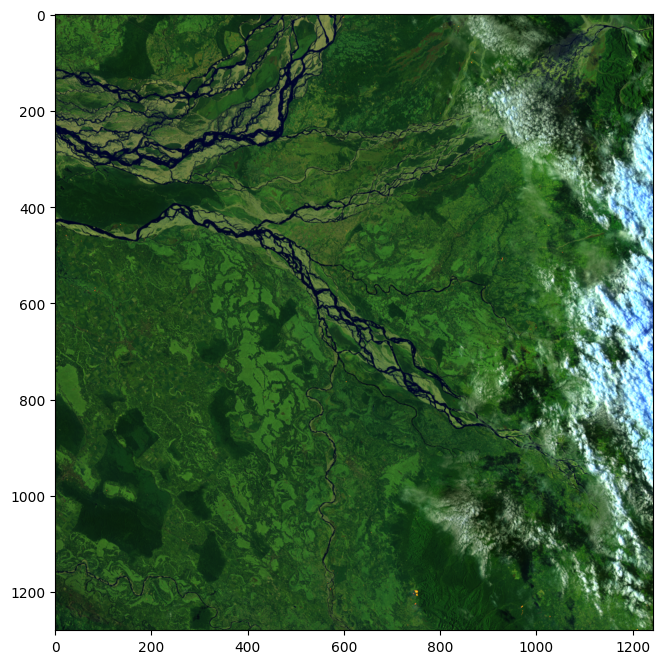

In [6]:
# DISPLAYING THE IMAGE FROM THREE BANDS ("USING THE GEOLOGICAL BAND COMBINATION SWIR-2, SWIR-1 & VIS-GREEN")

r, g, b = band(2325), band(1650), band(550)        # or plain indices, e.g. 35, 20, 10
print(f"R = band {r} at {wl[r]:.1f} nm,  G = band {g} at {wl[g]:.1f} nm,  B = band {b} at {wl[b]:.1f} nm")

plt.figure(figsize=(8, 8)); plt.imshow(stretch(img[:, :, [r, g, b]]))

Text(0, 0.5, 'Reflectance')

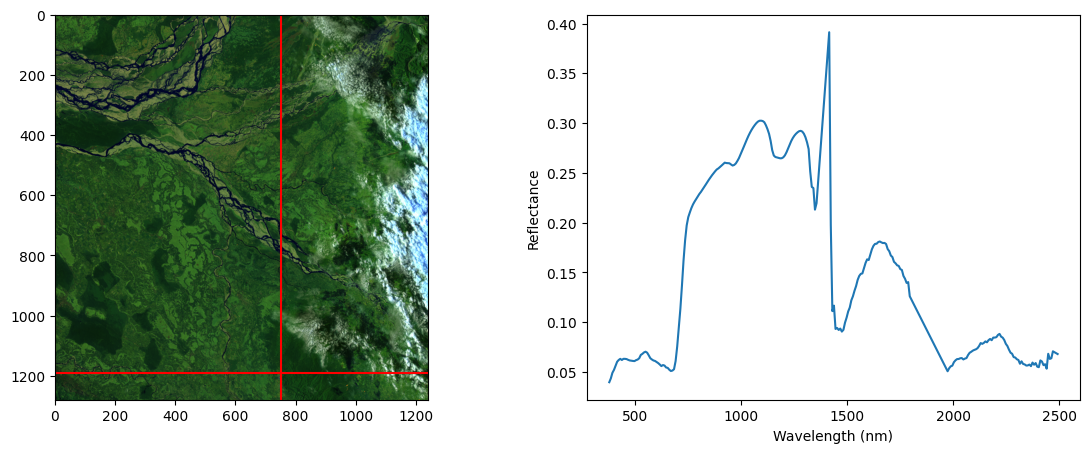

In [7]:
# PLOTTING THE SPECTRUM OF ONE PIXEL

row, col = 1190, 750
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1); 
plt.imshow(stretch(img[:, :, [r, g, b]]))
plt.axhline(row, color="r"); plt.axvline(col, color="r")

plt.subplot(1, 2, 2); 
plt.plot(wl, img[row, col, :]); plt.xlabel("Wavelength (nm)"); plt.ylabel("Reflectance")

(200, 200, 255) -> (40000, 255)


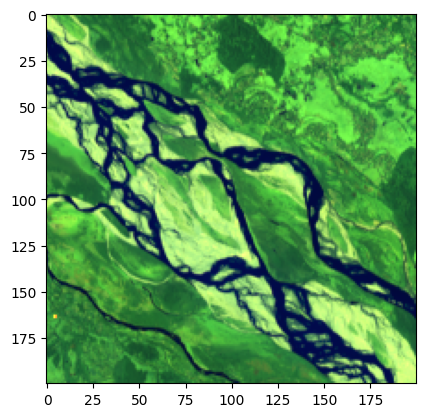

In [8]:
# CROPPING A SMALL AREA FROM THE CUBE AND TURNING THE CUBE INTO A TABLE

row0, col0, size = 600, 600, 200
cube = img[row0:row0 + size, col0:col0 + size]
X    = cube.reshape(-1, cube.shape[2])                         # (pixels, bands)
# X = cube.reshape(size * size, cube.shape[2])     #alternative way to convert into table.
print(cube.shape, "->", X.shape); plt.imshow(stretch(cube[:, :, [r, g, b]]))

Text(0, 0.5, '1648 nm')

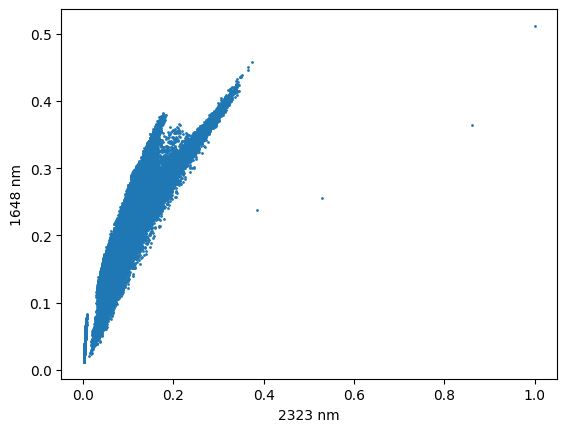

In [9]:
# PREPARING 2D SCATTER PLOT WHERE EVERY PIXEL IS A POINT AND TWO WAVELENGTHS ARE THE AXES (MUTUALLY PERPENDICULAR): POINT CLOUD CREATION

b1, b2 = r, g
plt.scatter(X[:, b1], X[:, b2], s=1)
plt.xlabel(f"{wl[b1]:.0f} nm"); plt.ylabel(f"{wl[b2]:.0f} nm")

In [11]:
# PREPARING 3D SCATTER PLOT

b1, b2, b3 = r, g, b
px.scatter_3d(x=X[:, b1], y=X[:, b2], z=X[:, b3], height=600,
              labels=dict(x=f"{wl[b1]:.0f} nm", y=f"{wl[b2]:.0f} nm", z=f"{wl[b3]:.0f} nm")).update_traces(marker_size=1)

Text(0, 0.5, 'Reflectance')

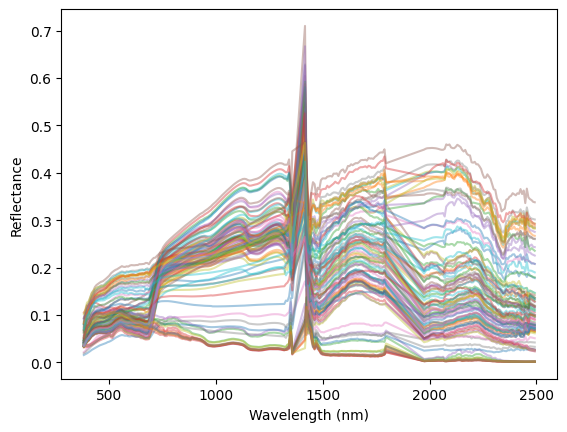

In [12]:
# SPECTRA FOR 100 RANDOM PIXELS
n = 100
idx = np.random.choice(len(X), n, replace=False)      # n random pixels from the table X
plt.plot(wl, X[idx].T, alpha=0.4); plt.xlabel("Wavelength (nm)"); plt.ylabel("Reflectance")

SHARP PEAK DUE TO WATER VAPOR EDGE ARTIFACT, APART 2 DISTINCT POPULATION: HIGH REFLECTANCE POPULATION (~0.4 -0.5) &
LOW REFLECTANCE POPULATION (~0.1 to 0.3) NARROW DIAGNOSTIC ABSOPRTION FEATURES.

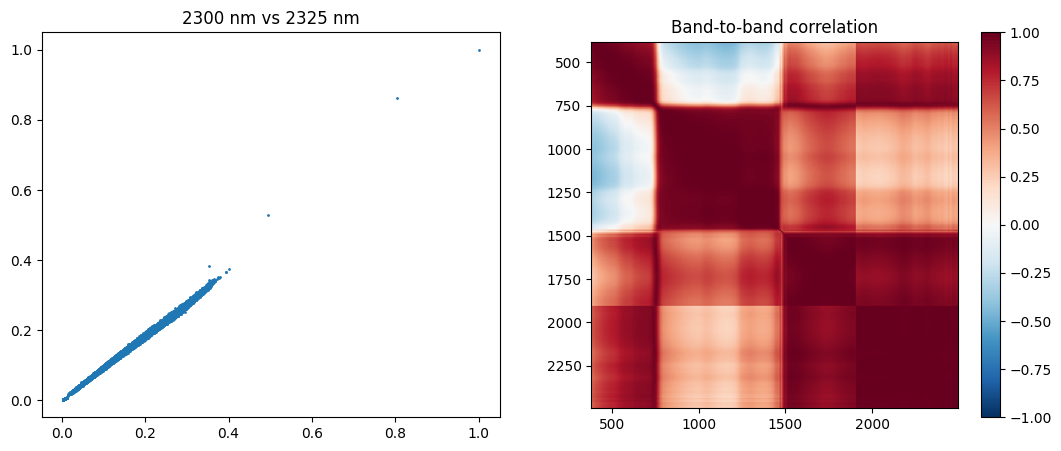

In [13]:
# DATA LIVE ON FAR FEWER DIMENSION (AMBIENT) THAN THE NUMBER OF BANDS
# BAND TO BAND CORRELATION TO SEPARATE OUT REDUNDANT INFORMATION AS NEIGHBORING BANDS CARRY NEARLY SAME INFORMATION

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1); plt.scatter(X[:, band(2300)], X[:, band(2325)], s=1); plt.title("2300 nm vs 2325 nm")
plt.subplot(1, 2, 2); plt.imshow(np.corrcoef(X.T), cmap="RdBu_r", vmin=-1, vmax=1, extent=[wl[0], wl[-1], wl[-1], wl[0]])
plt.title("Band-to-band correlation"); plt.colorbar()

LEFT - EXTREME TIGHT NEAR DIAGONAL LINE OF POINTS CONFIRMING ADJACENT SPECTRAL BANDS ARE HIGHLY REDUNDANT
RIGHT - PEARSON CORRELATION WHERE LARGE RED BLOCKS REPRESENTS ALL BANDS RISE AND FALL TOGETHER UNIFORMLY (REFLECTANCE OVERALL BRIGHT OR OVERALL LOW). LIGHT RED BANDS SHOW POSITIVE CORRELATION AS WHEN REFLECTACNE INCREASES IN ONE OF THESE BANDS, IT INCREASES IN OTHERS AS WELL. BLUISH ZONES ARE REPRESENTING NEGATIVE CORRELATION, WHEN A PIXEL'S REFLECTANCE GOES UP IN ONE WAVELENGTH, IT GOES DOWN IN OTHER WAVELENGTH

In [14]:
# PCA
n_pc = 50
pca = PCA(n_components=n_pc).fit(X); P = pca.transform(X)       # P = (pixels, n_pc)

The first 4 PCs hold 99.24% of the variance of 255 bands


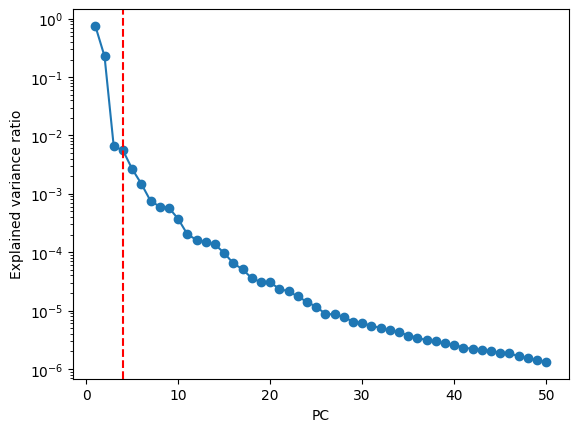

In [15]:
# SCREE PLOT
elbow = 4 # Although we specify this value in the beginning, but it has to be diceded based on the output of the scree plot in the nexr cell's output.
plt.plot(range(1, n_pc + 1), pca.explained_variance_ratio_, "o-")
plt.yscale("log")
plt.axvline(elbow, color="r", ls="--")
plt.xlabel("PC"); plt.ylabel("Explained variance ratio")
print(f"The first {elbow} PCs hold {pca.explained_variance_ratio_[:elbow].sum():.2%} of the variance of {X.shape[1]} bands")

FIRST 4 PCs CAPTURE 99.24% OF THE TOTAL STATISTICAL VARIANCE FROM ORIGINAL 255 BANDS THUS VALIDATES BAND TO BAND REDUNDANCY.
Y AXIS ON LOG SCALE - EACH HORIZONTAL LINE REPRESENTS 10 FOLD DROP IN VARIANCE. STEEP DOWNWARD SLOPE SHOWS DROPPING OFF OF INFORMATION CONTENT EXPONENTIALLY AFTER FIRST TWO COMPONENTS.
THE ELBOW (RED-DASHED LINE) AT PC=4 MARKS CUT-OFF POINT. RETAINING COMPONENTS PAST THIS ELBOW YIELDS DIMINISHING RETURNS, AS SUBSEQUENT COMPONENTS CONTRIBUTE NEGLIGIBLE UNIQUE VARIANCE.

Text(0.5, 1.0, 'PC0 as an image')

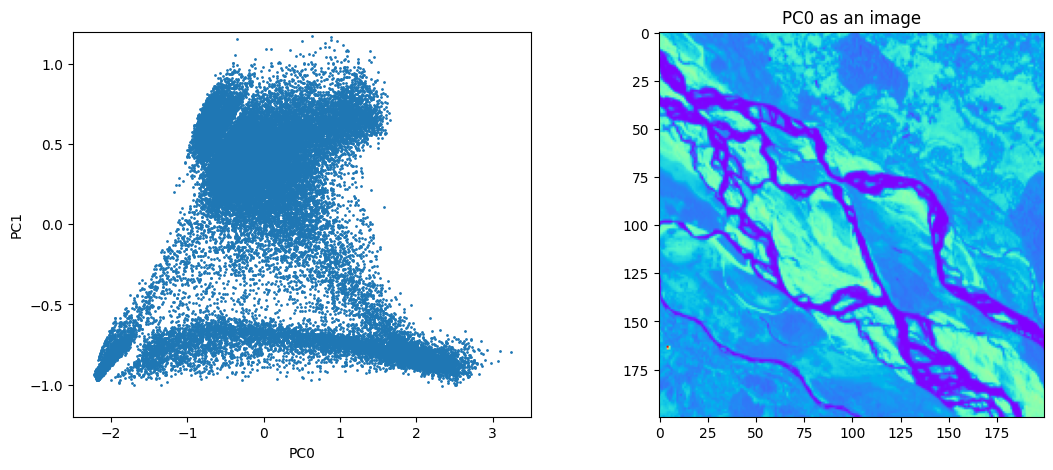

In [17]:
# SCATTERING TWO PC'S AGAINST EACH OTHER
pc_a, pc_b = 0, 1
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1); plt.scatter(P[:, pc_a], P[:, pc_b], s=1); plt.xlabel(f"PC{pc_a}"); plt.ylabel(f"PC{pc_b}"); plt.xticks([-2, -1, 0, 1, 2, 3]); plt.xlim([-2.5, 3.5]); plt.yticks([-1, -0.5, 0, 0.5, 1]); plt.ylim([-1.2, 1.2])
plt.subplot(1, 2, 2); plt.imshow(P[:, pc_a].reshape(size, size), cmap="rainbow"); plt.title(f"PC{pc_a} as an image")

IN THE SCATTER PLOT, THE DENSE POPULATION REPRESENTS DOMINANCE OF SOME SAMPLE ROCK TYPE. THE UPPER WELL DEFINED ARM INDICATING DISTINCT PHASE WITH UNIQUE SPECTRAL SLOPE VARIATIONS. THE LOWER EXTENDING BRANCH SPLITS DOWNWARD SHOWING SOME EXPRESSION THAT DIVERGES COMPLETELY FROM REST OF THE ROCK MATRIX (SAY ALTERATION).

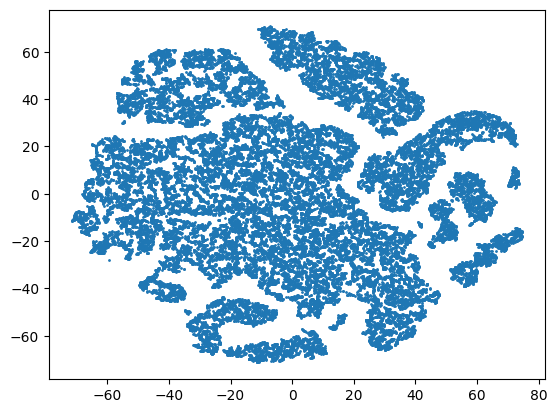

In [18]:
# t-SNE

# To find non-linearity in 2 or 3 Dimensions; Structure of the data at local scale (t-distributed Stochastic Neighbour Embedding)

n_pcs_used         = elbow       # how many PCs go into t-SNE (1 to n_pc)
perplexity         = 40          # roughly how many neighbours each point considers (5–50)
early_exaggeration = 20          # how hard clusters are pushed apart at the start (≥1; try 4–30)
learning_rate      = "auto"      # step size: "auto" or a number (10–1000)
max_iter           = 750        # number of iterations (must be at least 250)
init               = "random"    # starting layout: "pca" or "random"
random_state       = 0           # same number = same map every run; change it to see another layout

T = TSNE(n_components=2, perplexity=perplexity, early_exaggeration=early_exaggeration,
         learning_rate=learning_rate, max_iter=max_iter, init=init,
         random_state=random_state).fit_transform(P[:, :n_pcs_used])
plt.scatter(T[:, 0], T[:, 1], s=1)

THE ANALYSIS SUCCESSFULLY UNCOVERED HIGHLY DISTINCT LOCALIZED SUB-POPULATIONS (CLUSTERS) WITHIN THE DATASET THAT WERE BLENDED TOGETHER IN PCA. PIXELS ARE SEEN SPLIT INTO MULTIPLE ISOLATED DISCRETE CLUSTERS RATHER THAN A CONTINUOUS CLOUD. THIS MEANS THE DATASET IS COMPOSED OF HIGHLY DISTINCT SPECTRAL CLASSES.

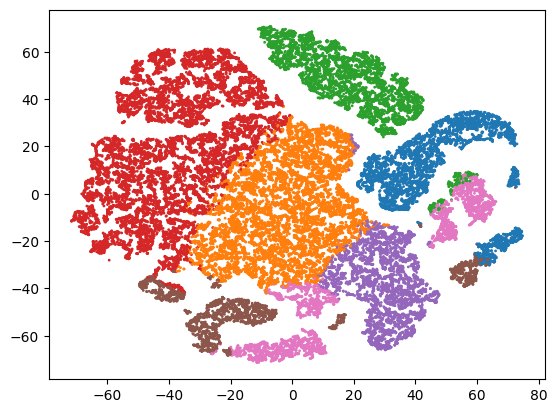

In [19]:
# K-MEANS ON T-SNE MAP
k = 7
labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(P[:, :n_pcs_used])     # try .fit_predict(P[:, :n_pcs_used]) and compare!
plt.scatter(T[:, 0], T[:, 1], s=1, c=labels, cmap="tab10", vmin=0, vmax=9)

SUCCESSFULLY CLASSIFIED THE DATASET INTO 7 DISTINCT SPECTRAL CLASSES, WHICH ALIGN WELL WITH THE ISOLATED PATCHES BY T-SNE MAPPING.

Text(0.5, 1.0, 'k-means, k = 7')

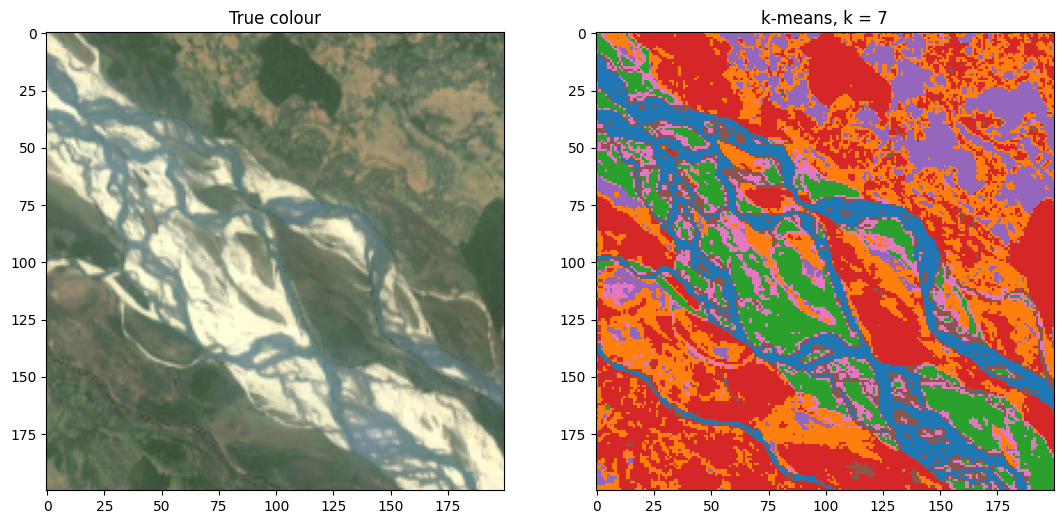

In [20]:
# ORIGINAL IMAGE VS CLASSIFIED IMAGE
plt.figure(figsize=(13, 6))
plt.subplot(1, 2, 1); plt.imshow(stretch(cube[:, :, [band(650), band(560), band(470)]])); plt.title("True colour")
plt.subplot(1, 2, 2); plt.imshow(labels.reshape(size, size), cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); plt.title(f"k-means, k = {k}")

Text(0, 0.5, 'Mean reflectance')

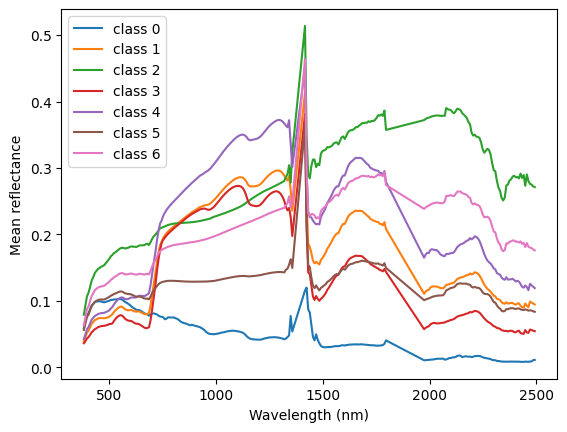

In [21]:
# MEAN SPECTRUM PER CLUSTER
for i in range(k): plt.plot(wl, X[labels == i].mean(0), color=plt.cm.tab10(i), label=f"class {i}")
plt.legend(); plt.xlabel("Wavelength (nm)"); plt.ylabel("Mean reflectance")